In [1]:
%matplotlib inline
!pip install opencv-python
!pip install PyMuPDF
!pip install matplotlib
!pip install pypdf
import matplotlib.pyplot as plt
import os
import cv2
import numpy as np
import fitz
from pypdf import PdfReader, PdfWriter
import time
import json


In [2]:
import sys
sys.path.append('../src')

from pdf_set import PDFSet

In [3]:
data = PDFSet.fromFolder('../case_outputs/yellow', 'fitz numpy300 ')

[TASK] Loading 0: ../case_outputs/yellow/1_VINAR JEFFERY 98456120 2025 2 18.pdf into fitz done.
[TASK] Loading 1: ../case_outputs/yellow/7_PREUCIL WILLIAM 60122817 2025 3 5.pdf into fitz done.
[TASK] Loading 2: ../case_outputs/yellow/0_PROSS THOMAS 70068060 2025 3 12.pdf into fitz done.
[TASK] Loading 3: ../case_outputs/yellow/5_SPRADLIN QUINCI 07161475 2025 3 24.pdf into fitz done.
[TASK] Loading 4: ../case_outputs/yellow/3_SETISURAL RAN 24119765 2025 3 18.pdf into fitz done.
[TASK] Loading 5: ../case_outputs/yellow/2_SKIBBE TREVYN 20371161 2025 3 25.pdf into fitz done.
[TASK] Loading 6: ../case_outputs/yellow/8_PETERSON JESSICA 21724670 2025 3 10.pdf into fitz done.
[TASK] Loading 7: ../case_outputs/yellow/9_WALSH JOHN 24217485 2025 4 10.pdf into fitz done.
[TASK] Loading 0: ../case_outputs/yellow/1_VINAR JEFFERY 98456120 2025 2 18.pdf into numpy done.
[TASK] Loading 1: ../case_outputs/yellow/7_PREUCIL WILLIAM 60122817 2025 3 5.pdf into numpy done.
[TASK] Loading 2: ../case_outputs/y

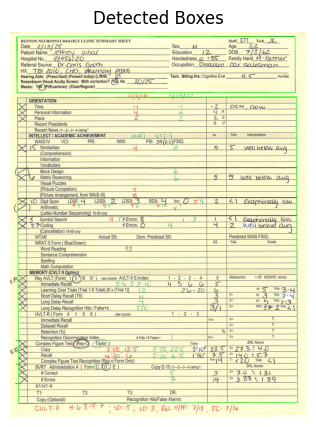

In [4]:
#### Follows grayscale -> blur -> threshold -> contour

pdf, img, fn = data[0,0]
img = img.copy()

def rect_bound(approx) -> tuple[np.ndarray, int]:
    x, y, w, h = cv2.boundingRect(approx)
    box = np.array([
        [x, y],
        [x + w, y],
        [x + w, y + h],
        [x, y + h]
    ])
    return box, w*h

def para_bound(approx) -> tuple[np.ndarray, int]:
    rect = cv2.minAreaRect(approx)  # note: use the original contour, not approx
    box = cv2.boxPoints(rect)
    box = np.intp(box)
    (_, _), (w, h), _ = rect
    return box, w*h


# Reduce image channels
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) if img.ndim == 3 else img

# Reduce image noise
blur = cv2.GaussianBlur(gray, (5, 5), 0) 

# Define adaptive threshold to convert image to BW, adjust for light
thresh = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                               cv2.THRESH_BINARY_INV, 15, 10)

# Find external contours, and compress information
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

boxes = []
valids = 0
for contour in contours:
    # Simplify contour shape to retrieve bounding polygon
    approx = cv2.approxPolyDP(contour, 0.0395 * cv2.arcLength(contour, True), True)
    if len(approx) == 4 and cv2.isContourConvex(approx):
        valids += 1
        box, area = para_bound(approx)
        if area > 10000:
            cv2.drawContours(img, [box], 0, (0, 255, 0), 3)
            boxes.append(box)



plt.figure(figsize=(5,5))
plt.imshow(img)
plt.axis("off")
plt.title("Detected Boxes")
plt.show()


In [7]:
template = '../configs/template2025.json'

with open(template) as f:
    config = json.load(f)

"""
Notes:
Anchors should be ordered from smallest to largest expected area. This is the current method to identify them
"""

config




{'format_id': '2025',
 'anchors': ['top_box', 'bottom_box'],
 'censor': [{'name': 'Patient Name',
   'relative_to': 'top_box',
   'topleft': [0, -40],
   'bottomright': [200, 30]},
  {'name': 'DOB',
   'relative_to': 'top_box',
   'topleft': [100, 20],
   'bottomright': [300, 35]}]}